In [1]:
import numpy as np
print(np.__version__)
print(np.__file__)

2.5.1
C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\numpy\__init__.py


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,InputLayer
from tensorflow.keras.datasets import fashion_mnist

In [17]:
items = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
         'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [3]:
(train_images,train_labels),(test_images,test_labels)=fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 15s 1us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [4]:
train_images.shape

(60000, 28, 28)

In [5]:
test_images.shape

(10000, 28, 28)

In [7]:
print('minimum pixel:',train_images.min())
print('maximum pixel:',train_images.max())

minimum pixel: 0
maximum pixel: 255


In [8]:
train_images,test_images=train_images/255.0,test_images/255.0

In [9]:
print('minimum pixel value:',train_images.min())
print('maximum pixel value:',train_images.max())

minimum pixel value: 0.0
maximum pixel value: 1.0


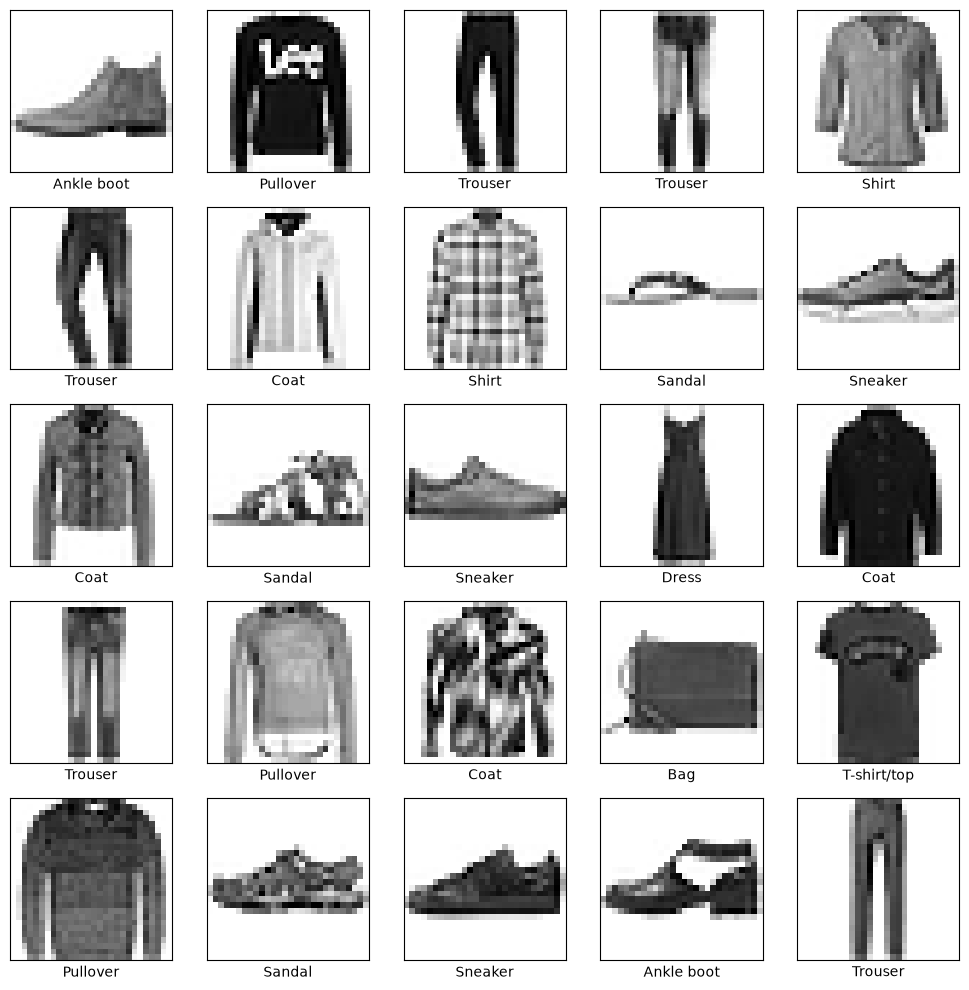

In [33]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(test_images[i], cmap=plt.cm.binary)
    plt.xlabel(items[test_labels[i]])

plt.tight_layout()
plt.show()

In [11]:
model=Sequential()
model.add(InputLayer(input_shape=(28,28,1)))
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dense(10,activation='softmax'))
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\keras\src\layers\core\input_layer.py:29: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(
C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,554 (236.54 KB)

 Trainable params: 60,554 (236.54 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.fit(train_images,train_labels,epochs=5,validation_data=(test_images,test_labels))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 50s 26ms/step - accuracy: 0.7890 - loss: 0.5787 - val_accuracy: 0.8403 - val_loss: 0.4455
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 51s 27ms/step - accuracy: 0.8553 - loss: 0.3971 - val_accuracy: 0.8628 - val_loss: 0.3783
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 84s 28ms/step - accuracy: 0.8746 - loss: 0.3391 - val_accuracy: 0.8714 - val_loss: 0.3536
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 50s 27ms/step - accuracy: 0.8873 - loss: 0.3024 - val_accuracy: 0.8782 - val_loss: 0.3345
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 25ms/step - accuracy: 0.8983 - loss: 0.2738 - val_accuracy: 0.8793 - val_loss: 0.3347


In [14]:
predicted=model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step


In [15]:
predicted.shape

(10000, 10)

In [19]:
pred=np.argmax(predicted,axis=1)

In [20]:
pred.shape

(10000,)

In [21]:
loss,accuracy=model.evaluate(test_images,test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8793 - loss: 0.3347


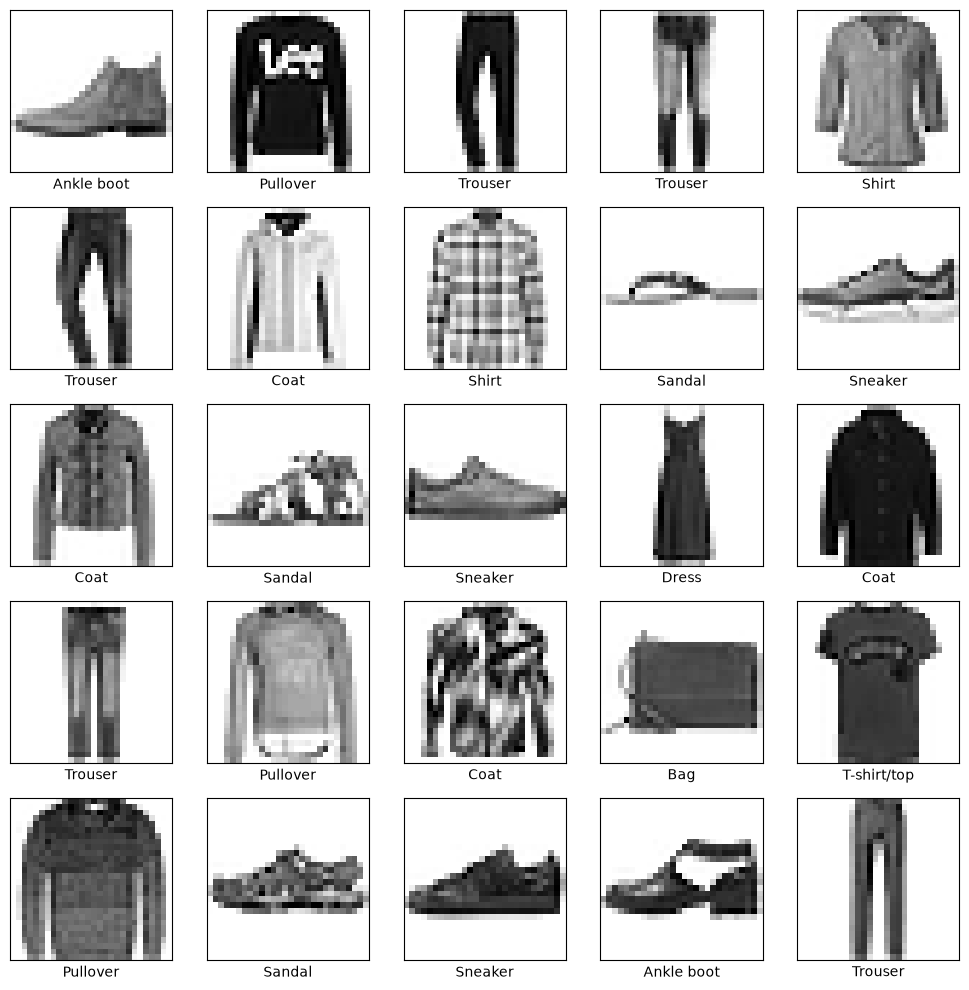

In [25]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(test_images[i], cmap=plt.cm.binary)
    plt.xlabel(items[test_labels[i]])

plt.tight_layout()
plt.show()

In [26]:
cm=confusion_matrix(test_labels,pred)
cm

array([[866,   0,  27,  35,   3,   1,  58,   0,  10,   0],
       [  6, 960,   2,  27,   2,   0,   1,   0,   2,   0],
       [ 12,   0, 849,  18,  47,   0,  61,   0,  13,   0],
       [ 16,   2,  25, 920,   9,   0,  23,   0,   4,   1],
       [  3,   0,  94,  46, 787,   0,  54,   0,  16,   0],
       [  0,   0,   0,   3,   0, 960,   0,  24,   0,  13],
       [156,   0,  90,  36, 113,   0, 566,   0,  39,   0],
       [  0,   0,   0,   0,   0,  12,   0, 938,   0,  50],
       [  0,   0,   2,   4,   2,   8,   1,   2, 981,   0],
       [  1,   0,   0,   0,   0,   8,   0,  25,   0, 966]])

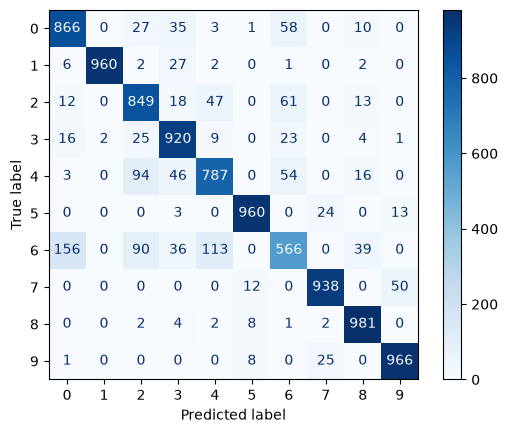

In [27]:
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

In [28]:
total = cm.sum()

correct = np.trace(cm)

incorrect = total - correct

print("Total:", total)
print("Correct:", correct)
print("Incorrect:", incorrect)

Total: 10000
Correct: 8793
Incorrect: 1207


In [29]:
import numpy as np

incorrect_indices = np.where(test_labels != pred)[0]

print("Number of incorrect images:", len(incorrect_indices))

Number of incorrect images: 1207


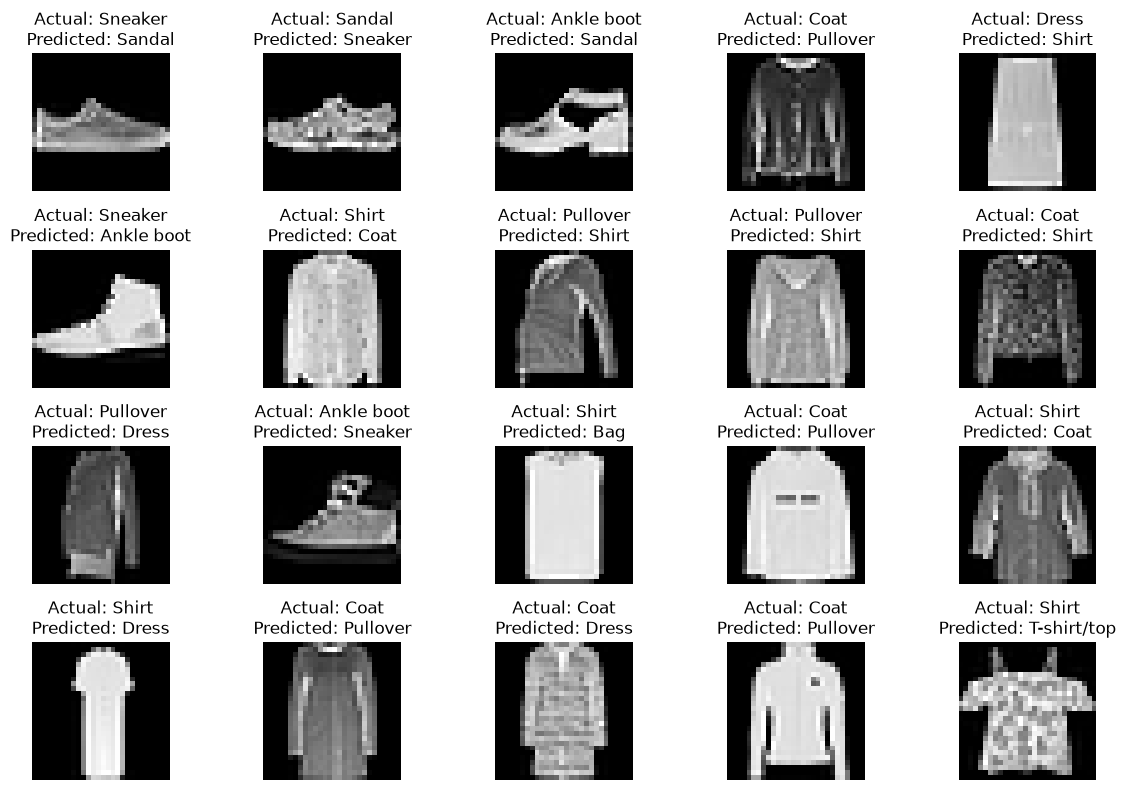

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, index in enumerate(incorrect_indices[:20]):
    plt.subplot(4, 5, i + 1)
    
    plt.imshow(test_images[index].reshape(28, 28), cmap='gray')
    
    plt.title(f"Actual: {items[test_labels[index]]}\nPredicted: {items[pred[index]]}")
    plt.axis('off')

plt.tight_layout()
plt.show()